In [20]:
import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch.nn as nn 
from torchvision import models,transforms
import copy
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx 
import pickle
import torch.nn.functional as F

In [21]:
df = pd.read_csv("plants_metadata_clean.csv")

In [22]:
image_root = "../plants/data"

In [23]:
classes = sorted(df["species"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["label"] = df["species"].map(class_to_idx)

print(len(classes), "classes,", len(df), "images")
print(df["split"].value_counts())

14 classes, 132 images
split
train    92
test     26
val      14
Name: count, dtype: int64


In [24]:
IMG_SIZE = 224
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

In [25]:
class PlantDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(image_root, row["filename"])).convert("RGB")
        return self.transform(img), int(row["label"])

In [ ]:
train_ds = PlantDataset(df[df["split"] == "train"], train_tf)
val_ds   = PlantDataset(df[df["split"] == "val"],   eval_tf)
test_ds  = PlantDataset(df[df["split"] == "test"],  eval_tf)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=16)
test_loader  = DataLoader(test_ds,  batch_size=16)

print(len(train_ds), len(val_ds), len(test_ds))

92 14 26


torch.Size([16, 3, 224, 224]) tensor([12, 10,  7,  5,  6, 12,  3, 12])


In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

num_classes = len(classes)
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model = model.to(device)

Using: cpu


In [28]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

def run_epoch(loader, train=False, optimizer=None):
    model.train(train)
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

In [29]:
best_acc, best_state = 0, None

In [30]:
def train_phase(epochs, lr, name):
    global best_acc, best_state
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4
    )
    for ep in range(epochs):
        tr_loss, tr_acc = run_epoch(train_loader, True, optimizer)
        va_loss, va_acc = run_epoch(val_loader)
        print(f"[{name}] ep {ep+1}/{epochs}  train {tr_loss:.3f}/{tr_acc:.2f}  val {va_loss:.3f}/{va_acc:.2f}")
        if va_acc >= best_acc:
            best_acc, best_state = va_acc, copy.deepcopy(model.state_dict())

In [ ]:
# Phase 1: backbone frozen, train only the new classifier head
for p in model.features.parameters():
    p.requires_grad = False
train_phase(epochs=10, lr=1e-3, name="head")

# Phase 2: unfreeze the last blocks and fine-tune with a small learning rate
for p in model.features[5:].parameters():
    p.requires_grad = True
train_phase(epochs=15, lr=1e-4, name="finetune")

model.load_state_dict(best_state)
torch.save(model.state_dict(), "plant_classifier.pth")

import json
json.dump(classes, open("classes.json", "w"))

Accuracy: 0.6153846153846154
Macro F1: 0.4741496598639456
Weighted F1: 0.526007326007326
                          precision    recall  f1-score   support

   Alysicarpus vaginalis       1.00      1.00      1.00         2
Gomphocarpus physocarpus       0.40      1.00      0.57         2
      Hemidesmus indicus       0.00      0.00      0.00         1
      Libidibia coriaria       1.00      1.00      1.00         2
      Lotus corniculatus       1.00      1.00      1.00         2
Macroptilium lathyroides       0.00      0.00      0.00         1
           Mimosa hamata       0.00      0.00      0.00         2
           Mimosa pudica       0.50      1.00      0.67         2
        Trigonella emodi       0.50      1.00      0.67         1
    Vachellia farnesiana       0.00      0.00      0.00         1
   Vachellia leucophloea       0.00      0.00      0.00         2
      Vachellia nilotica       0.50      0.33      0.40         3
           Vigna radiata       0.50      1.00      0

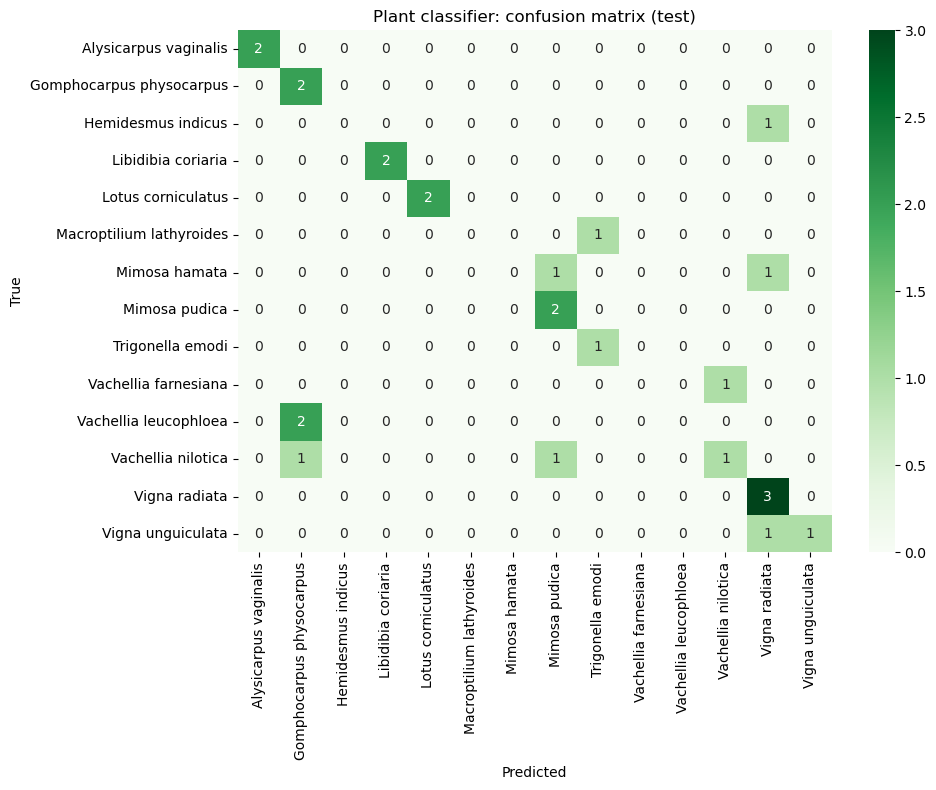

In [ ]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Macro F1:", f1_score(y_true, y_pred, average="macro", zero_division=0))
print("Weighted F1:", f1_score(y_true, y_pred, average="weighted", zero_division=0))
print(classification_report(y_true, y_pred, labels=range(num_classes),
                            target_names=classes, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Plant classifier: confusion matrix (test)")
plt.xticks(rotation=90); plt.tight_layout()
plt.savefig("../plots/confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
test_df = df[df["split"] == "test"].reset_index(drop=True)
errors = pd.DataFrame({
    "true": [classes[t] for t in y_true],
    "pred": [classes[p] for p in y_pred],
    "file": test_df["filename"],
})
print(errors[errors["true"] != errors["pred"]].to_string())

                        true                      pred                                                                             file
4         Hemidesmus indicus             Vigna radiata                     plants/images/Hemidesmus_indicus/Hemidesmus_indicus_hero.jpg
9   Macroptilium lathyroides          Trigonella emodi  plants/images/Macroptilium_lathyroides/Macroptilium_lathyroides_gallery_002.jpg
10             Mimosa hamata             Vigna radiata                        plants/images/Mimosa_hamata/Mimosa_hamata_gallery_003.jpg
11             Mimosa hamata             Mimosa pudica                        plants/images/Mimosa_hamata/Mimosa_hamata_gallery_002.jpg
15      Vachellia farnesiana        Vachellia nilotica          plants/images/Vachellia_farnesiana/Vachellia_farnesiana_gallery_001.jpg
16     Vachellia leucophloea  Gomphocarpus physocarpus        plants/images/Vachellia_leucophloea/Vachellia_leucophloea_gallery_005.jpg
17     Vachellia leucophloea  Gomphocarpus physo

In [ ]:
model.eval()
hits = 0
with torch.no_grad():
    for x, y in test_loader:
        top3 = model(x.to(device)).topk(3, dim=1).indices.cpu()
        hits += (top3 == y.unsqueeze(1)).any(dim=1).sum().item()
print("Top-3 accuracy:", hits / len(test_ds))

Top-3 accuracy: 0.7307692307692307


In [ ]:
edges = pd.read_csv("plant_butterfly_edges.csv")
hosts = edges.groupby("species")["butterfly_species"].apply(set)

def host_overlap(a, b):
    return len(hosts[a] & hosts[b]) / len(hosts[a] | hosts[b])

print(host_overlap("Mimosa hamata", "Mimosa pudica"))  # swap in pairs from the error list

0.0


In [ ]:
edges = pd.read_csv("plant_butterfly_edges.csv")
unique_edges = edges[["species", "butterfly_species"]].drop_duplicates()
print(len(unique_edges), "unique plant-butterfly pairs")

hosts = unique_edges.groupby("species")["butterfly_species"].apply(set)
print(hosts.apply(len).sort_values())      # hosts per plant

wrong = errors[errors["true"] != errors["pred"]]
for _, r in wrong.iterrows():
    a, b = r["true"], r["pred"]
    j = len(hosts[a] & hosts[b]) / len(hosts[a] | hosts[b])
    print(f"{a:26s} -> {b:26s} overlap {j:.2f}")

54 unique plant-butterfly pairs
species
Alysicarpus vaginalis        1
Gomphocarpus physocarpus     1
Hemidesmus indicus           1
Macroptilium lathyroides     1
Trigonella emodi             1
Mimosa hamata                2
Vachellia farnesiana         2
Vigna radiata                3
Mimosa pudica                4
Vigna unguiculata            4
Vachellia leucophloea        6
Lotus corniculatus           6
Vachellia nilotica           7
Libidibia coriaria          15
Name: butterfly_species, dtype: int64
Hemidesmus indicus         -> Vigna radiata              overlap 0.00
Macroptilium lathyroides   -> Trigonella emodi           overlap 0.00
Mimosa hamata              -> Vigna radiata              overlap 0.00
Mimosa hamata              -> Mimosa pudica              overlap 0.00
Vachellia farnesiana       -> Vachellia nilotica         overlap 0.12
Vachellia leucophloea      -> Gomphocarpus physocarpus   overlap 0.00
Vachellia leucophloea      -> Gomphocarpus physocarpus   overlap 0.0

In [ ]:
def jaccard(a, b):
    return len(hosts[a] & hosts[b]) / len(hosts[a] | hosts[b])

scores = []
for t, p in zip(y_true, y_pred):
    a, b = classes[t], classes[p]
    scores.append(1.0 if a == b else jaccard(a, b))

print("Mean advisory agreement:", sum(scores) / len(scores))
print("Predictions with zero host overlap:", sum(s == 0 for s in scores), "/", len(scores))

Mean advisory agreement: 0.6266025641025641
Predictions with zero host overlap: 8 / 26


In [ ]:
plants = pd.read_csv("plants_metadata_clean.csv")
bflies = pd.read_csv("butterflies_metadata_clean.csv")
edges  = pd.read_csv("plant_butterfly_edges.csv")[["species", "butterfly_species"]].drop_duplicates()

# taxonomy: one row per butterfly species
tax = (bflies.drop_duplicates("species")
             .set_index("species")[["common_name", "family", "subfamily", "genus"]])
plant_info = plants.drop_duplicates("species").set_index("species")["family"]

G = nx.DiGraph()

# plant nodes
for sp in edges["species"].unique():
    G.add_node(sp, kind="plant", family=plant_info.get(sp))

# butterfly nodes (some have no metadata/images; they still get a node)
for sp in edges["butterfly_species"].unique():
    attrs = tax.loc[sp].to_dict() if sp in tax.index else {}
    G.add_node(sp, kind="butterfly", has_metadata=sp in tax.index, **attrs)

# plant -> butterfly "hosts" edges
for _, r in edges.iterrows():
    G.add_edge(r["species"], r["butterfly_species"], relation="hosts")

# state nodes + "recorded_in" edges, weighted by number of images
for df_, kind in [(plants, "plant"), (bflies, "butterfly")]:
    counts = df_.groupby(["species", "state"]).size().reset_index(name="n")
    for _, r in counts.iterrows():
        if r["species"] in G:
            G.add_node(r["state"], kind="state")
            G.add_edge(r["species"], r["state"], relation="recorded_in", n_images=int(r["n"]))

print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())
print({k: sum(1 for _, d in G.nodes(data=True) if d["kind"] == k) for k in ["plant", "butterfly", "state"]})
print("Butterflies without metadata:", [n for n, d in G.nodes(data=True)
                                        if d["kind"] == "butterfly" and not d["has_metadata"]])

# sanity check on one plant
print(list(G.successors("Mimosa pudica")))

pickle.dump(G, open("knowledge_graph.pkl", "wb"))

Nodes: 86 | Edges: 562
{'plant': 14, 'butterfly': 39, 'state': 33}
Butterflies without metadata: ['Charaxes bharata', 'Hypolimnas bolina', 'Hypolimnas misippus', 'Junonia orithya', 'Charaxes agrarius', 'Neptis hylas']
['Prosotas dubiosa', 'Junonia hierta', 'Junonia orithya', 'Eurema hecabe', 'Andhra Pradesh', 'Karnataka', 'Maharashtra']


In [ ]:
raw = pd.read_csv("../butterflies/data/butterflies/metadata.csv")   # add "../" if your notebook is in a subfolder
for sp in ["Junonia orithya", "Neptis hylas"]:
    sub = raw[raw["species"].str.contains(sp.split()[1], case=False, na=False)]
    print(sp, "->", len(sub), "rows;", sub["species"].unique()[:5])
    print(sub[["family", "subfamily", "genus", "life_stage", "location"]].isnull().sum().to_dict())

Junonia orithya -> 56 rows; ['Junonia orithya swinhoei' 'Junonia orithya ocyale']
{'family': 56, 'subfamily': 56, 'genus': 56, 'life_stage': 56, 'location': 0}
Neptis hylas -> 24 rows; ['Neptis hylas varmona']
{'family': 24, 'subfamily': 24, 'genus': 24, 'life_stage': 24, 'location': 0}


In [ ]:
raw["species_base"] = raw["species"].str.split().str[:2].str.join(" ")
fix = ["Junonia orithya", "Neptis hylas"]
sub = raw[raw["species_base"].isin(fix)]

for sp in fix:
    s = sub[sub["species_base"] == sp]
    genus = sp.split()[0]
    cn = s["common_name"].dropna().mode()
    congener = bflies[bflies["genus"] == genus]          # same-genus species already cleaned
    attrs = dict(
        common_name=cn.iloc[0] if len(cn) else sp,
        genus=genus,
        family=congener["family"].iloc[0] if len(congener) else None,
        subfamily=congener["subfamily"].iloc[0] if len(congener) else None,
        has_metadata=True,
    )
    G.nodes[sp].update(attrs)
    print(sp, attrs)

    for state, n in s.dropna(subset=["state"]).groupby("state").size().items():
        G.add_node(state, kind="state")
        G.add_edge(sp, state, relation="recorded_in", n_images=int(n))

pickle.dump(G, open("knowledge_graph.pkl", "wb"))
print("Butterflies without metadata:", [n for n, d in G.nodes(data=True)
      if d["kind"] == "butterfly" and not d["has_metadata"]])

Junonia orithya {'common_name': 'Pale Blue Pansy', 'genus': 'Junonia', 'family': 'Nymphalidae', 'subfamily': 'Nymphalinae', 'has_metadata': True}
Neptis hylas {'common_name': 'Indian Common Sailer', 'genus': 'Neptis', 'family': None, 'subfamily': None, 'has_metadata': True}
Butterflies without metadata: ['Charaxes bharata', 'Hypolimnas bolina', 'Hypolimnas misippus', 'Charaxes agrarius']


In [ ]:
root = "../butterflies/data/butterflies/images"
print([d for d in os.listdir(root) if d.startswith(("Junonia_orithya", "Neptis_hylas"))])

['Junonia_orithya', 'Neptis_hylas']


In [ ]:
nep = raw[raw["species"].str.startswith("Neptis", na=False) & raw["family"].notna()]
print(nep[["species", "family", "subfamily"]].drop_duplicates())

                   species       family      subfamily
38395        Neptis ananta  Nymphalidae  Limenitidinae
38465       Neptis cartica  Nymphalidae  Limenitidinae
38488        Neptis clinia  Nymphalidae  Limenitidinae
38564        Neptis harita  Nymphalidae  Limenitidinae
38616         Neptis melba  Nymphalidae  Limenitidinae
38626          Neptis nata  Nymphalidae  Limenitidinae
38683       Neptis nycteus  Nymphalidae  Limenitidinae
38702  Neptis pseudovikasi  Nymphalidae  Limenitidinae
38780         Neptis radha  Nymphalidae  Limenitidinae
38794       Neptis sankara  Nymphalidae  Limenitidinae
38840        Neptis sappho  Nymphalidae  Limenitidinae


In [ ]:
G.nodes["Neptis hylas"].update(family="Nymphalidae", subfamily="Limenitidinae")   # use the verified values
pickle.dump(G, open("knowledge_graph.pkl", "wb"))

In [ ]:
with open("knowledge_graph.pkl", "rb") as f:
    G = pickle.load(f)

In [ ]:
WESTERN_GHATS = {"Maharashtra", "Karnataka", "Kerala", "Goa", "Tamil Nadu"}

def recorded_states(G, node):
    return {s: G.edges[node, s]["n_images"]
            for s in G.successors(node)
            if G.edges[node, s]["relation"] == "recorded_in"}

def retrieve(G, plant):
    states = recorded_states(G, plant)
    out = {
        "plant": plant,
        "family": G.nodes[plant].get("family"),
        "plant_states_wg": sorted(s for s in states if s in WESTERN_GHATS),
        "plant_states_other": sorted(s for s in states if s not in WESTERN_GHATS),
        "butterflies": [],
    }
    for b in G.successors(plant):
        if G.edges[plant, b]["relation"] != "hosts":
            continue
        d = G.nodes[b]
        bs = recorded_states(G, b)
        out["butterflies"].append({
            "species": b,
            "common_name": d.get("common_name"),
            "family": d.get("family"),
            "states_wg": sorted(s for s in bs if s in WESTERN_GHATS),
            "has_image_data": d.get("has_metadata", False) and bool(bs),
        })
    return out

import json
print(json.dumps(retrieve(G, "Mimosa pudica"), indent=2))

{
  "plant": "Mimosa pudica",
  "family": "Fabaceae",
  "plant_states_wg": [
    "Karnataka",
    "Maharashtra"
  ],
  "plant_states_other": [
    "Andhra Pradesh"
  ],
  "butterflies": [
    {
      "species": "Prosotas dubiosa",
      "common_name": "Indian Tailless Lineblue",
      "family": "Lycaenidae",
      "states_wg": [
        "Goa",
        "Karnataka",
        "Kerala",
        "Maharashtra",
        "Tamil Nadu"
      ],
      "has_image_data": true
    },
    {
      "species": "Junonia hierta",
      "common_name": "Oriental Yellow Pansy",
      "family": "Nymphalidae",
      "states_wg": [
        "Karnataka",
        "Kerala",
        "Maharashtra",
        "Tamil Nadu"
      ],
      "has_image_data": true
    },
    {
      "species": "Junonia orithya",
      "common_name": "Pale Blue Pansy",
      "family": "Nymphalidae",
      "states_wg": [
        "Karnataka",
        "Kerala",
        "Maharashtra"
      ],
      "has_image_data": true
    },
    {
      "specie

In [ ]:
def predict_top3(image_path):
    img = Image.open(image_path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0]
    p, i = probs.topk(3)
    return [(classes[k], float(v)) for v, k in zip(p, i)]

HIGH, LOW = 0.60, 0.30     # placeholders, set from validation data (below)

def advise_inputs(image_path):
    top3 = predict_top3(image_path)
    conf = top3[0][1]
    if conf >= HIGH:
        return {"tier": "high", "facts": [retrieve(G, top3[0][0])], "top3": top3}
    if conf >= LOW:
        return {"tier": "medium", "facts": [retrieve(G, n) for n, _ in top3], "top3": top3}
    return {"tier": "low", "facts": [], "top3": top3}

In [41]:
model.eval()
rows = []
with torch.no_grad():
    for x, y in val_loader:
        pr = F.softmax(model(x.to(device)), dim=1).cpu()
        conf, pred = pr.max(1)
        rows += [(float(c), int(p == t)) for c, p, t in zip(conf, pred, y)]
print(sorted(rows))

[(0.17767870426177979, 1), (0.22457869350910187, 1), (0.29791679978370667, 0), (0.38709700107574463, 0), (0.5979095101356506, 1), (0.6153872609138489, 0), (0.6746227741241455, 1), (0.7551577687263489, 1), (0.8053442239761353, 1), (0.8493790626525879, 1), (0.9061650037765503, 1), (0.9192068576812744, 1), (0.9245579838752747, 1), (0.9477704167366028, 1)]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classes = json.load(open("classes.json"))

model = models.efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(classes))
model.load_state_dict(torch.load("plant_classifier.pth", map_location=device))
model = model.to(device).eval()

IMG_SIZE = 224
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

In [40]:
def evaluate(loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in loader:
            y_pred += model(x.to(device)).argmax(1).cpu().tolist()
            y_true += y.tolist()
    acc = sum(int(a == b) for a, b in zip(y_true, y_pred)) / len(y_true)
    return acc, y_true, y_pred

print("val acc :", evaluate(val_loader)[0])    # saved checkpoint should give ~0.79
print("test acc:", evaluate(test_loader)[0])   # earlier run gave 0.615 (16/26)

val acc : 0.7857142857142857
test acc: 0.6153846153846154


In [42]:
HIGH, LOW = 0.65, 0.30
def tier_of(c): return "high" if c >= HIGH else "medium" if c >= LOW else "low"

model.eval()
rows = []
with torch.no_grad():
    for x, y in test_loader:
        pr = F.softmax(model(x.to(device)), dim=1).cpu()
        conf, pred = pr.max(1)
        top3 = pr.topk(3, dim=1).indices
        for c, p, t, t3 in zip(conf, pred, y, top3):
            rows.append(dict(conf=float(c), tier=tier_of(float(c)),
                             correct=int(p == t), top3_hit=int(int(t) in t3.tolist())))
res = pd.DataFrame(rows)

print("overall top-1:", res["correct"].mean())      # should be 0.615 (16/26)
print(res.groupby("tier").agg(n=("correct", "size"), top1=("correct", "mean"), top3=("top3_hit", "mean")))

overall top-1: 0.6153846153846154
         n      top1      top3
tier                          
high     8  0.875000  0.875000
low      7  0.285714  0.285714
medium  11  0.636364  0.909091


In [49]:
import requests, json

SYSTEM = """You write short trail-side advisories for trekkers in the Western Ghats.
Use ONLY the facts in the JSON you are given. Never add species, places or ecological claims that are not in it.
The one general statement you may make is that caterpillars of the listed butterflies feed on this plant,
so trampling it removes their food.
Say 'recorded as a host' (never 'depends only on'). Use Latin names if a common name is missing.
If a butterfly has no states_wg, don't mention its location. Plain language, no blame, 3-4 sentences."""


def llm_chat(system, user, model="llama3.2"):
    r = requests.post(
        "http://localhost:11434/api/chat",
        json={
            "model": model,
            "stream": False,
            "options": {"temperature": 0.2, "num_predict": 400},
            "messages": [{"role": "system", "content": system},
                         {"role": "user", "content": user}],
        },
        timeout=120,
    )
    r.raise_for_status()
    return r.json()["message"]["content"]

def write_advisory(inputs):
    if inputs["tier"] == "low":
        return "I'm not sure which plant this is. Please retake the photo, closer and in daylight."
    payload = {
        "tier": inputs["tier"],
        "model_candidates": [{"plant": n, "confidence": round(p, 2)} for n, p in inputs["top3"]],
        "facts": inputs["facts"],
    }
    task = ("The model is confident. Write the advisory for the identified plant."
            if inputs["tier"] == "high" else
            "The model is unsure. Say the identification is uncertain, name the candidate plants, "
            "mention each candidate's recorded butterflies in one line, and ask the user to confirm.")
    
    return llm_chat(SYSTEM, f"{task}\n\n{json.dumps(payload, indent=2)}")

In [50]:
sample = df[df["split"] == "test"]["filename"].iloc[0]
inputs = advise_inputs(os.path.join(image_root, sample))
print(inputs["tier"], inputs["top3"])
print(write_advisory(inputs))

medium [('Alysicarpus vaginalis', 0.41028308868408203), ('Trigonella emodi', 0.0887053981423378), ('Vigna radiata', 0.07755818963050842)]
**Uncertain Plant Identification**

We're not sure which plant you're standing next to. Here are our top candidates:

* Alysicarpus vaginalis (Fabaceae) - recorded as a host for Zizina otis (Indian Lesser Grass Blue)
* Trigonella emodi (Fabaceae) - recorded as a host for Colias fieldii (Himalayan Dark Clouded Yellow)
* Vigna radiata (Fabaceae) - recorded as a host for Euchrysops cnejus (Oriental Gram Blue), Jamides celeno (Oriental Common Cerulean), and Zizina otis (Indian Lesser Grass Blue)

Can you please confirm which plant you think you're standing next to?
